# Early Sepsis Detection: Dataset Audit

This notebook audits the locally available PhysioNet/CinC 2019 Sepsis Prediction patient files before preprocessing or predictive modeling. Training Set A and Training Set B remain separate throughout. No imputation, normalization, discretization, predictive window construction, pattern mining, or model fitting is performed.

## 1. Project and Dataset Overview

The audit discovers patient-level `.psv` files below `data/raw/training_setA/` and `data/raw/training_setB/`, reads them one at a time, and saves reproducible tables and figures under `outputs/audit/` and `outputs/figures/`.

In [1]:
from pathlib import Path
import json
import random
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

RANDOM_SEED = 42
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)
warnings.filterwarnings("ignore", category=RuntimeWarning)


def find_repository_root():
    current = Path.cwd().resolve()
    for candidate in [current, *current.parents]:
        if (candidate / "data" / "raw").exists():
            return candidate
    raise FileNotFoundError("Could not locate the repository root.")


ROOT = find_repository_root()
DATA_ROOT = ROOT / "data" / "raw"
AUDIT_DIR = ROOT / "outputs" / "audit"
FIGURE_DIR = ROOT / "outputs" / "figures"
AUDIT_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
SET_DIRS = {"Training A": DATA_ROOT / "training_setA", "Training B": DATA_ROOT / "training_setB"}
for set_name, set_dir in SET_DIRS.items():
    if not set_dir.exists():
        raise FileNotFoundError(f"Missing {set_name} directory: {set_dir}")

print(f"Repository root: {ROOT}")
print(f"Random seed: {RANDOM_SEED}")

Repository root: E:\ssdproject
Random seed: 42


## 2. Imports and Configuration

All paths are derived from the repository root. The raw files are read only.

## 3. Dataset Discovery

In [2]:
file_map = {}
discovery_rows = []
for set_name, set_dir in SET_DIRS.items():
    files = sorted(set_dir.rglob("*.psv"))
    file_map[set_name] = files
    sizes = np.array([path.stat().st_size for path in files], dtype=float)
    discovery_rows.append({
        "training_set": set_name,
        "psv_files": len(files),
        "unique_patient_files": len({path.name.lower() for path in files}),
        "file_size_bytes_min": sizes.min() if sizes.size else np.nan,
        "file_size_bytes_max": sizes.max() if sizes.size else np.nan,
        "file_size_bytes_mean": sizes.mean() if sizes.size else np.nan,
        "file_size_bytes_median": np.median(sizes) if sizes.size else np.nan,
    })
    print(f"{set_name}: discovered {len(files):,} .psv files")
discovery_summary = pd.DataFrame(discovery_rows)
display(discovery_summary)

Training A: discovered 20,336 .psv files
Training B: discovered 20,000 .psv files


,training_set,psv_files,unique_patient_files,file_size_bytes_min,file_size_bytes_max,file_size_bytes_mean,file_size_bytes_median
0,Training A,20336,20336,1528.0,55325.0,6460.892211,6419.0
1,Training B,20000,20000,1476.0,53131.0,6183.439000,6227.0


## 4. Representative File Inspection

In [3]:
representative_files = {}
schemas = {}
for set_name, files in file_map.items():
    sample = random.Random(RANDOM_SEED).sample(files, min(2, len(files)))
    representative_files[set_name] = sample
    print(f"\n{set_name} representative files: {[path.name for path in sample]}")
    for path in sample:
        frame = pd.read_csv(path, sep="|")
        print(f"\n{path.name}: {frame.shape[0]:,} rows x {frame.shape[1]} columns")
        print("Has SepsisLabel:", "SepsisLabel" in frame.columns, "Has ICULOS:", "ICULOS" in frame.columns, "Has HospAdmTime:", "HospAdmTime" in frame.columns)
        display(frame.head())
        display(pd.DataFrame({"dtype": frame.dtypes.astype(str), "non_null": frame.notna().sum(), "missing": frame.isna().sum()}))
        display(frame.describe(include="all").T.head(10))
    schema_frame = pd.read_csv(files[0], sep="|", nrows=5)
    schemas[set_name] = {"columns": list(schema_frame.columns), "dtypes": schema_frame.dtypes.astype(str).to_dict()}
schema_a = schemas["Training A"]["columns"]
schema_b = schemas["Training B"]["columns"]
print(f"\nTraining A columns: {len(schema_a)}; Training B columns: {len(schema_b)}; identical schemas: {schema_a == schema_b}")
print("Columns only in A:", sorted(set(schema_a) - set(schema_b)))
print("Columns only in B:", sorted(set(schema_b) - set(schema_a)))


Training A representative files: ['p003649.psv', 'p000820.psv']

p003649.psv: 32 rows x 41 columns
Has SepsisLabel: True Has ICULOS: True Has HospAdmTime: True


,HR,O2Sat,Temp,SBP,MAP,DBP,Resp,EtCO2,BaseExcess,HCO3,...,WBC,Fibrinogen,Platelets,Age,Gender,Unit1,Unit2,HospAdmTime,ICULOS,SepsisLabel
0,88.0,100.0,36.80,124.0,82.0,58.0,12.0,NaN,NaN,26.0,...,9.7,NaN,168.0,67.51,1,0,1,-750.25,5,0
1,89.5,100.0,36.65,115.0,77.5,57.0,12.5,NaN,3.0,NaN,...,NaN,NaN,NaN,67.51,1,0,1,-750.25,6,0
2,88.0,100.0,36.70,110.0,75.0,55.0,12.0,NaN,0.0,NaN,...,NaN,NaN,NaN,67.51,1,0,1,-750.25,7,0
3,77.0,100.0,36.95,107.0,74.0,55.0,12.0,NaN,NaN,NaN,...,NaN,NaN,NaN,67.51,1,0,1,-750.25,8,0
4,83.0,100.0,37.00,100.0,69.0,52.5,12.0,NaN,NaN,NaN,...,NaN,NaN,NaN,67.51,1,0,1,-750.25,9,0


,dtype,non_null,missing
HR,float64,32,0
O2Sat,float64,31,1
Temp,float64,22,10
SBP,float64,32,0
MAP,float64,32,0
DBP,float64,30,2
Resp,float64,32,0
EtCO2,float64,0,32
BaseExcess,float64,7,25
HCO3,float64,2,30


,count,mean,std,min,25%,50%,75%,max
HR,32.0,92.156250,6.298281,77.00,89.8750,91.00,95.6250,106.50
O2Sat,31.0,97.387097,2.249851,92.00,96.0000,97.00,100.0000,100.00
Temp,22.0,37.382727,0.629998,35.83,36.9625,37.50,37.9500,38.20
SBP,32.0,98.156250,11.803798,83.00,90.3750,96.00,101.0625,136.75
MAP,32.0,66.671562,7.329465,54.00,63.0000,65.75,69.3725,86.67
DBP,30.0,51.050000,6.607663,39.00,47.1250,51.00,55.0000,67.50
Resp,32.0,17.656250,5.249328,10.00,12.0000,18.75,21.5000,29.00
EtCO2,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
BaseExcess,7.0,3.000000,2.449490,0.00,1.5000,3.00,4.5000,6.00
HCO3,2.0,27.000000,1.414214,26.00,26.5000,27.00,27.5000,28.00



p000820.psv: 23 rows x 41 columns
Has SepsisLabel: True Has ICULOS: True Has HospAdmTime: True


...


p100820.psv: 58 rows x 41 columns
Has SepsisLabel: True Has ICULOS: True Has HospAdmTime: True


,HR,O2Sat,Temp,SBP,MAP,DBP,Resp,EtCO2,BaseExcess,HCO3,...,WBC,Fibrinogen,Platelets,Age,Gender,Unit1,Unit2,HospAdmTime,ICULOS,SepsisLabel
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,84,1,0,1,-166.63,1,0
1,75.0,95.0,36.1,124.0,68.0,48.0,14.0,NaN,NaN,NaN,...,NaN,NaN,NaN,84,1,0,1,-166.63,2,0
2,79.0,100.0,36.7,123.0,68.0,48.0,15.0,NaN,NaN,NaN,...,NaN,NaN,NaN,84,1,0,1,-166.63,3,0
3,70.0,100.0,NaN,111.0,62.0,47.0,14.0,NaN,NaN,NaN,...,11.9,NaN,91.0,84,1,0,1,-166.63,4,0
4,72.0,100.0,NaN,118.0,62.0,43.0,14.0,NaN,NaN,NaN,...,NaN,NaN,NaN,84,1,0,1,-166.63,5,0


,dtype,non_null,missing
HR,float64,57,1
O2Sat,float64,57,1
Temp,float64,20,38
SBP,float64,57,1
MAP,float64,57,1
DBP,float64,57,1
Resp,float64,56,2
EtCO2,float64,0,58
BaseExcess,float64,0,58
HCO3,float64,0,58


,count,mean,std,min,25%,50%,75%,max
HR,57.0,71.236842,1.581436,70.0,70.0,71.00,72.000,79.0
O2Sat,57.0,98.377193,2.000626,92.0,97.0,99.00,100.000,100.0
Temp,20.0,36.087500,0.272356,35.6,36.0,36.00,36.125,36.7
SBP,57.0,130.447368,9.456991,107.0,125.0,132.00,136.000,151.0
MAP,57.0,71.938596,5.756262,61.0,68.0,71.00,75.000,86.5
DBP,57.0,53.228070,6.492489,39.0,48.0,53.00,56.000,72.5
Resp,56.0,15.580357,1.958146,11.0,14.0,15.25,17.000,20.0
EtCO2,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
BaseExcess,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
HCO3,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN



Training A columns: 41; Training B columns: 41; identical schemas: True
Columns only in A: []
Columns only in B: []


## 5. Clinical Variable Inventory, Missingness, and Quality Helpers

In [5]:
KNOWN_GROUPS = {
    "Vital signs": {"HR", "O2Sat", "Temp", "SBP", "MAP", "DBP", "Resp", "EtCO2", "FiO2", "pH", "PaCO2", "SaO2"},
    "Laboratory measurements": {"BaseExcess", "HCO3", "AST", "BUN", "Alkalinephos", "Calcium", "Chloride", "Creatinine", "Bilirubin_direct", "Glucose", "Lactate", "Magnesium", "Phosphate", "Potassium", "Bilirubin_total", "TroponinI", "Hct", "Hgb", "PTT", "WBC", "Fibrinogen", "Platelets"},
    "Demographic/static information": {"Age", "Gender", "Unit1", "Unit2"},
    "Time/context variables": {"HospAdmTime", "ICULOS"},
    "Target label": {"SepsisLabel"},
}
NONNEGATIVE_VARIABLES = set().union(*KNOWN_GROUPS.values()) - {"HospAdmTime"}

def classify_variable(column):
    for group, columns in KNOWN_GROUPS.items():
        if column in columns:
            return group
    return "Other / not classified by name"

def new_accumulator():
    return {"records": 0, "patients": 0, "files_with_errors": 0, "column_stats": {}, "sequence_lengths": [], "patient_rows": [], "quality_rows": [], "label_rows": [], "observed_counts": [], "missing_counts": [], "negative_values": {}}

def update_stats(stats_by_column, frame, column):
    values = pd.to_numeric(frame[column], errors="coerce")
    valid = values.dropna()
    stats = stats_by_column.setdefault(column, {"non_null": 0, "missing": 0, "sum": 0.0, "min": np.nan, "max": np.nan})
    stats["non_null"] += int(valid.size)
    stats["missing"] += int(values.isna().sum())
    if valid.size:
        stats["sum"] += float(valid.sum())
        stats["min"] = float(valid.min()) if pd.isna(stats["min"]) else min(stats["min"], float(valid.min()))
        stats["max"] = float(valid.max()) if pd.isna(stats["max"]) else max(stats["max"], float(valid.max()))

def audit_patient(path, set_name, acc):
    quality = {"training_set": set_name, "patient_file": path.name, "file_size_bytes": path.stat().st_size, "read_error": "", "empty_file": False, "duplicate_rows": 0, "unexpected_column_count": False, "missing_ICULOS": False, "non_monotonic_ICULOS": False, "missing_SepsisLabel": False, "invalid_SepsisLabel_values": 0, "invalid_numeric_values": 0, "negative_physiological_values": 0}
    try:
        frame = pd.read_csv(path, sep="|")
    except Exception as exc:
        quality["read_error"] = f"{type(exc).__name__}: {exc}"
        acc["files_with_errors"] += 1
        acc["quality_rows"].append(quality)
        return
    if frame.empty:
        quality["empty_file"] = True
        acc["quality_rows"].append(quality)
        return
    acc["patients"] += 1
    rows = len(frame)
    acc["records"] += rows
    acc["sequence_lengths"].append(rows)
    quality["duplicate_rows"] = int(frame.duplicated().sum())
    quality["unexpected_column_count"] = len(frame.columns) != len(schema_a)
    observed = frame.notna().sum(axis=1)
    acc["observed_counts"].extend(observed.astype(int).tolist())
    acc["missing_counts"].extend((len(frame.columns) - observed).astype(int).tolist())
    for column in frame.columns:
        update_stats(acc["column_stats"], frame, column)
        numeric = pd.to_numeric(frame[column], errors="coerce")
        quality["invalid_numeric_values"] += int(frame[column].notna().sum() - numeric.notna().sum())
        if column in NONNEGATIVE_VARIABLES:
            count = int((numeric < 0).sum())
            quality["negative_physiological_values"] += count
            acc["negative_values"][column] = acc["negative_values"].get(column, 0) + count
    if "ICULOS" not in frame:
        quality["missing_ICULOS"] = True
        iculos = pd.Series(dtype=float)
    else:
        iculos = pd.to_numeric(frame["ICULOS"], errors="coerce")
        quality["missing_ICULOS"] = bool(iculos.isna().any())
        quality["non_monotonic_ICULOS"] = bool(iculos.dropna().diff().lt(0).any())
    if "SepsisLabel" not in frame:
        quality["missing_SepsisLabel"] = True
        labels = pd.Series(dtype=float)
    else:
        labels = pd.to_numeric(frame["SepsisLabel"], errors="coerce")
        quality["missing_SepsisLabel"] = bool(labels.isna().any())
        quality["invalid_SepsisLabel_values"] = int((labels.notna() & ~labels.isin([0, 1])).sum())
    positive = labels.eq(1)
    positive_hours = int(positive.sum())
    if positive_hours:
        first_positive = iculos[positive].min() if "ICULOS" in frame else int(np.flatnonzero(positive.to_numpy())[0])
        last_positive = iculos[positive].max() if "ICULOS" in frame else int(np.flatnonzero(positive.to_numpy())[-1])
    else:
        first_positive, last_positive = np.nan, np.nan
    acc["label_rows"].append({"training_set": set_name, "patient_file": path.name, "sequence_length": rows, "positive_hours": positive_hours, "negative_hours": rows - positive_hours, "has_sepsis": bool(positive_hours), "first_positive_hour": first_positive, "last_positive_hour": last_positive, "ICU_length": iculos.max() if len(iculos) else np.nan})
    acc["patient_rows"].append({"training_set": set_name, "patient_file": path.name, "sequence_length": rows, "has_sepsis": bool(positive_hours), "positive_hours": positive_hours, "mean_missingness_percent": float(frame.isna().mean().mean() * 100)})
    acc["quality_rows"].append(quality)

## 6. Full Streaming Audit

In [6]:
accumulators = {set_name: new_accumulator() for set_name in SET_DIRS}
for set_name, files in file_map.items():
    print(f"Auditing {set_name}: {len(files):,} files")
    for index, path in enumerate(files, start=1):
        audit_patient(path, set_name, accumulators[set_name])
        if index == 1 or index % 1000 == 0 or index == len(files):
            print(f"  processed {index:,}/{len(files):,}", end="\r")
    print()

def sequence_stats(values):
    values = np.asarray(values, dtype=float)
    return {"min_sequence_length": values.min() if values.size else np.nan, "max_sequence_length": values.max() if values.size else np.nan, "mean_sequence_length": values.mean() if values.size else np.nan, "median_sequence_length": np.median(values) if values.size else np.nan}

summary_rows = []
for set_name, acc in accumulators.items():
    discovery = discovery_summary.loc[discovery_summary["training_set"] == set_name].iloc[0].to_dict()
    summary_rows.append({"training_set": set_name, "psv_files": discovery["psv_files"], "unique_patient_files": discovery["unique_patient_files"], "total_hourly_records": acc["records"], "read_error_files": acc["files_with_errors"], **sequence_stats(acc["sequence_lengths"]), **{key: value for key, value in discovery.items() if key.startswith("file_size_")}})
dataset_summary = pd.DataFrame(summary_rows)
display(dataset_summary)

Auditing Training A: 20,336 files


KeyboardInterrupt: 

## 7. Variable Inventory, Missingness, Labels, and Patient Sequences

In [7]:
def build_column_summary(set_name, acc):
    rows = []
    for column, stats in acc["column_stats"].items():
        total = stats["non_null"] + stats["missing"]
        rows.append({"training_set": set_name, "variable": column, "category": classify_variable(column), "data_type": schemas[set_name]["dtypes"].get(column, "unknown"), "non_null_count": stats["non_null"], "missing_count": stats["missing"], "missing_percentage": stats["missing"] / max(total, 1) * 100, "minimum": stats["min"], "maximum": stats["max"], "mean": stats["sum"] / stats["non_null"] if stats["non_null"] else np.nan, "median": np.nan})
    return pd.DataFrame(rows)

column_summary = pd.concat([build_column_summary(name, acc) for name, acc in accumulators.items()], ignore_index=True)
missingness_summary = column_summary[["training_set", "variable", "category", "non_null_count", "missing_count", "missing_percentage"]]
patient_sequence_summary = pd.concat([pd.DataFrame(acc["patient_rows"]) for acc in accumulators.values()], ignore_index=True)
label_details = pd.concat([pd.DataFrame(acc["label_rows"]) for acc in accumulators.values()], ignore_index=True)
label_summary = label_details.groupby("training_set").agg(total_hourly_records=("sequence_length", "sum"), positive_SepsisLabel_records=("positive_hours", "sum"), patients_with_positive_label=("has_sepsis", "sum"), patients=("patient_file", "count")).reset_index()
label_summary["negative_SepsisLabel_records"] = label_summary["total_hourly_records"] - label_summary["positive_SepsisLabel_records"]
label_summary["positive_record_percentage"] = label_summary["positive_SepsisLabel_records"] / label_summary["total_hourly_records"] * 100
label_summary["patients_with_no_positive_label"] = label_summary["patients"] - label_summary["patients_with_positive_label"]
observed_variable_summary = pd.DataFrame([{"training_set": name, "observed_variable_count_min": min(acc["observed_counts"]), "observed_variable_count_max": max(acc["observed_counts"]), "observed_variable_count_mean": np.mean(acc["observed_counts"]), "observed_variable_count_median": np.median(acc["observed_counts"]), "missing_variable_count_min": min(acc["missing_counts"]), "missing_variable_count_max": max(acc["missing_counts"]), "missing_variable_count_mean": np.mean(acc["missing_counts"]), "missing_variable_count_median": np.median(acc["missing_counts"])} for name, acc in accumulators.items()])
onset_rows = label_details[label_details["has_sepsis"]].copy()
onset_rows["first_positive_relative_to_ICU_length"] = onset_rows["first_positive_hour"] / onset_rows["ICU_length"]
display(column_summary)
display(missingness_summary)
display(observed_variable_summary)
display(label_summary)
display(patient_sequence_summary.groupby(["training_set", "has_sepsis"])[["sequence_length", "mean_missingness_percent"]].describe())
display(onset_rows[["training_set", "patient_file", "first_positive_hour", "last_positive_hour", "positive_hours", "ICU_length", "first_positive_relative_to_ICU_length"]].head())

ValueError: min() iterable argument is empty

## 8. Data Quality Checks

In [ ]:
data_quality_report = pd.concat([pd.DataFrame(acc["quality_rows"]) for acc in accumulators.values()], ignore_index=True)
quality_counts = []
for set_name, group in data_quality_report.groupby("training_set"):
    for issue in ["read_error", "empty_file", "duplicate_rows", "unexpected_column_count", "missing_ICULOS", "non_monotonic_ICULOS", "missing_SepsisLabel", "invalid_SepsisLabel_values", "invalid_numeric_values", "negative_physiological_values"]:
        if issue == "read_error":
            affected = group[issue].ne("").sum()
        elif issue in {"duplicate_rows", "invalid_SepsisLabel_values", "invalid_numeric_values", "negative_physiological_values"}:
            affected = group[issue].gt(0).sum()
        else:
            affected = group[issue].eq(True).sum()
        quality_counts.append({"training_set": set_name, "issue": issue, "affected_files": int(affected)})
quality_issue_summary = pd.DataFrame(quality_counts)
display(quality_issue_summary[quality_issue_summary["affected_files"] > 0])
for set_name, acc in accumulators.items():
    print(set_name, "negative values:", {key: value for key, value in acc["negative_values"].items() if value})

## 9. Training Set A vs B Comparison and Visualizations

,Metric,Training A,Training B
0,Mean missingness %,68.221175,NaN
1,Mean sequence length,39.043201,NaN
2,Median sequence length,38.000000,NaN
3,Non-septic patients,1279.000000,0.0
4,Patients,1412.000000,0.0
5,Septic patient %,9.419263,0.0
6,Septic patients,133.000000,0.0
7,Total hourly records,55129.000000,0.0


C:\Users\salai_wciilqo\AppData\Local\Temp\ipykernel_3224\1451812496.py:24: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axes[1].boxplot(box_data, labels=["Non-septic", "Septic"], showfliers=False)


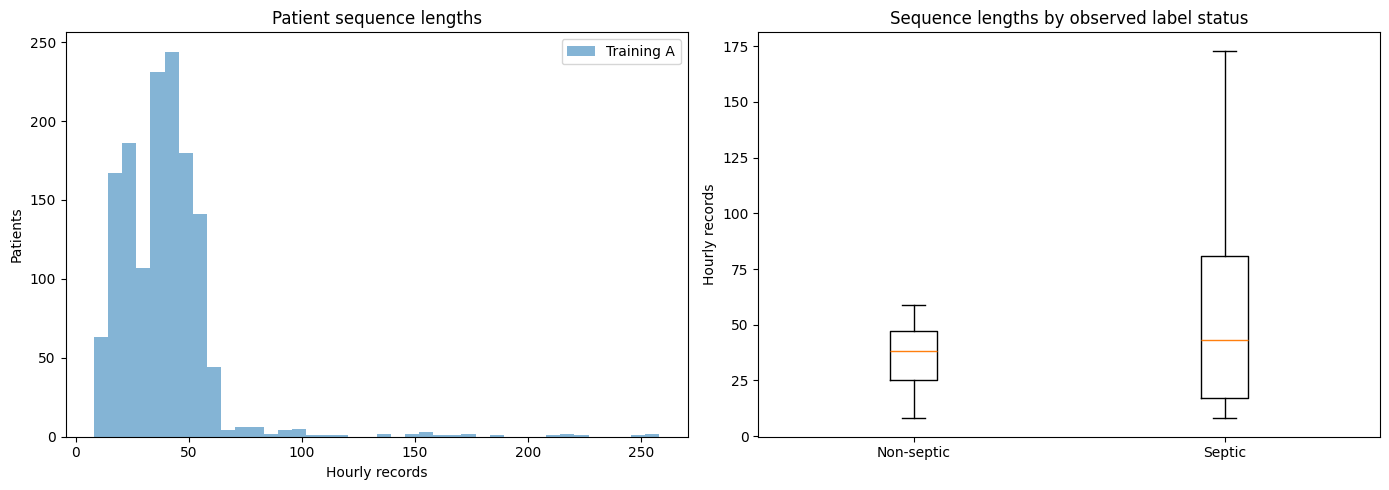

NameError: name 'onset_rows' is not defined

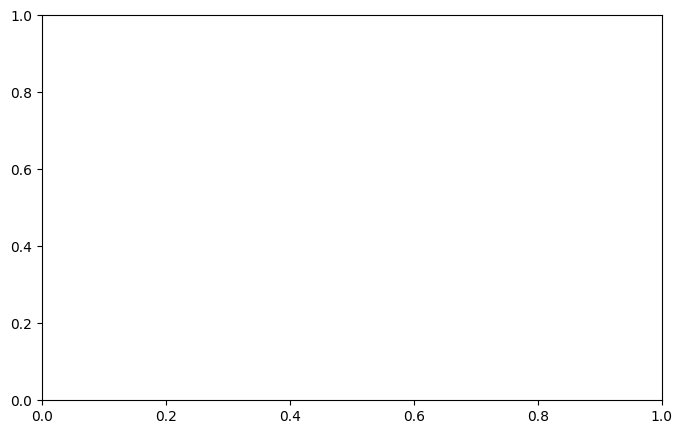

In [8]:
comparison_rows = []
for set_name, acc in accumulators.items():
    patients = patient_sequence_summary[patient_sequence_summary["training_set"] == set_name]
    septic = int(patients["has_sepsis"].sum())
    comparison_rows.extend([
        {"Metric": "Patients", set_name: len(patients)},
        {"Metric": "Total hourly records", set_name: acc["records"]},
        {"Metric": "Septic patients", set_name: septic},
        {"Metric": "Non-septic patients", set_name: len(patients) - septic},
        {"Metric": "Septic patient %", set_name: septic / max(len(patients), 1) * 100},
        {"Metric": "Mean sequence length", set_name: patients["sequence_length"].mean()},
        {"Metric": "Median sequence length", set_name: patients["sequence_length"].median()},
        {"Metric": "Mean missingness %", set_name: patients["mean_missingness_percent"].mean()},
    ])
set_comparison = pd.DataFrame(comparison_rows).groupby("Metric", as_index=False).first()
display(set_comparison)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for set_name, group in patient_sequence_summary.groupby("training_set"):
    axes[0].hist(group["sequence_length"], bins=40, alpha=0.55, label=set_name)
axes[0].set(title="Patient sequence lengths", xlabel="Hourly records", ylabel="Patients")
axes[0].legend()
box_data = [patient_sequence_summary.loc[patient_sequence_summary["has_sepsis"] == value, "sequence_length"] for value in [False, True]]
axes[1].boxplot(box_data, labels=["Non-septic", "Septic"], showfliers=False)
axes[1].set(title="Sequence lengths by observed label status", ylabel="Hourly records")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "sequence_length_distributions.png", dpi=150, bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(8, 5))
for set_name, group in onset_rows.groupby("training_set"):
    ax.hist(group["first_positive_hour"].dropna(), bins=30, alpha=0.55, label=set_name)
ax.set(title="Observable first positive label hour", xlabel="ICULOS at first SepsisLabel = 1", ylabel="Septic patients")
ax.legend()
fig.tight_layout()
fig.savefig(FIGURE_DIR / "first_positive_hour_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

missing_plot = missingness_summary.pivot(index="variable", columns="training_set", values="missing_percentage").sort_values(by="Training A", ascending=False)
fig, ax = plt.subplots(figsize=(12, 7))
missing_plot.plot.bar(ax=ax)
ax.set(title="Missingness percentage by variable", xlabel="Variable", ylabel="Missing (%)")
ax.tick_params(axis="x", rotation=75)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "missingness_by_variable.png", dpi=150, bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(7, 5))
label_counts = label_details.groupby("training_set")[["positive_hours", "negative_hours"]].sum()
label_counts.plot.bar(stacked=True, ax=ax, color=["#c44e52", "#4c72b0"])
ax.set(title="Hourly SepsisLabel distribution", xlabel="Training set", ylabel="Hourly records")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "sepsis_label_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

## 10. Save Audit Outputs

In [ ]:
outputs = {
    "dataset_summary.csv": dataset_summary,
    "column_summary.csv": column_summary,
    "missingness_summary.csv": missingness_summary,
    "observed_variable_summary.csv": observed_variable_summary,
    "label_summary.csv": label_summary,
    "patient_sequence_summary.csv": patient_sequence_summary,
    "sepsis_onset_summary.csv": onset_rows,
    "data_quality_report.csv": data_quality_report,
    "quality_issue_summary.csv": quality_issue_summary,
    "set_comparison.csv": set_comparison,
}
for filename, frame in outputs.items():
    frame.to_csv(AUDIT_DIR / filename, index=False)
metadata = {"random_seed": RANDOM_SEED, "repository_root": str(ROOT), "training_set_directories": {name: str(path) for name, path in SET_DIRS.items()}, "schemas_identical": schema_a == schema_b, "raw_files_modified": False, "imputation_performed": False, "predictive_modeling_performed": False}
(AUDIT_DIR / "audit_metadata.json").write_text(json.dumps(metadata, indent=2), encoding="utf-8")
print("Saved audit tables:")
for path in sorted(AUDIT_DIR.iterdir()):
    print(f"  {path.relative_to(ROOT)}")

## 11. Audit Summary and Next-Step Recommendations

The summary below reports only values calculated from the files currently present. Suspicious records are retained and reported rather than deleted. Training Set A and Training Set B remain separate; this audit does not choose a train/test split.

Next steps for Notebook 01 are to resolve missing-value handling, select variables using the observed missingness and quality tables, confirm the observable onset convention, and document a leakage-safe preprocessing design.